# Predicting Breast Cancer Recurrence from TCGA-BRCA Genomic and Clinical Data

**PredictMod ML Modeling Volunteership, Summer 2026**

This notebook builds a machine learning model that predicts whether a breast
cancer patient's disease will recur or progress after treatment, using clinical
information (age, tumor stage, hormone receptor status) together with mutation
status for 12 genes highlighted in the landmark 2012 TCGA breast cancer paper
("Comprehensive molecular portraits of human breast tumors," Nature, 2012).

**What this notebook covers, and how it maps to the project's weekly plan:**

- **Weeks 1 to 3** (dataset selection, extraction, and harmonization) happened
  in `hive_gwu (1).ipynb`, which pulls the raw TCGA-BRCA clinical and mutation
  files from cBioPortal's data export and merges them into one ML-ready table,
  `breast_cancer_ml_eda.csv`. This notebook picks up from that finished dataset.
- **Week 4** (model training): sections 1 through 10 below, three baseline
  models trained the way the modeling tutorial describes.
- **Week 5 to 6** (model performance improvement): section 11 onward, where we
  honestly test whether oversampling, extra models, and hyperparameter tuning
  actually help, and pick a final model and decision threshold based on what
  the data shows, not on what we hoped to see.
- **Weeks 7 to 8** (documentation, GitHub, single-patient prediction): the
  final model is saved to `model/dfs_model.joblib`, and the standalone script
  `predict_single_patient.py` in this same folder uses that saved file to score
  one new patient at a time. The BioCompute Object is in `model_bco.json`, and
  the full project write-up is in `README.md`.

Every code cell below has comments explaining not just *what* the line does,
but *why* that choice was made, since the goal of this notebook is as much to
document the reasoning as it is to produce a model.


## 1. Loading the data

In [1]:
%matplotlib inline
# Core data handling and plotting libraries used throughout the notebook.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# The dataset was originally read from a Google Drive path because this
# notebook was first developed in Google Colab. Running it locally instead,
# so we point it at the copy of the ML-ready CSV that lives in this same
# project folder. Using a relative path (no leading drive letter or "/content"
# prefix) means the notebook will still work if the whole project folder is
# moved or cloned somewhere else, which matters once this gets pushed to
# GitHub for the Week 8 submission.
df = pd.read_csv("breast_cancer_ml_eda.csv")
print("Loaded", df.shape[0], "patients and", df.shape[1], "columns.")
df.head()


Loaded 895 patients and 23 columns.


,PATIENT_ID,AGE,AJCC_PATHOLOGIC_TUMOR_STAGE,ER_STATUS_BY_IHC,PR_STATUS_BY_IHC,IHC_HER2,DFS_STATUS,SAMPLE_ID,CANCER_TYPE,CANCER_TYPE_DETAILED,...,GATA3,CDH1,PTEN,MAP3K1,MAP2K4,KRAS,KMT2C,ARID1A,RUNX1,ESR1
0,TCGA-3C-AALI,50.0,Stage IIB,Positive,Positive,Positive,0:DiseaseFree,TCGA-3C-AALI-01,Breast Cancer,Breast Invasive Ductal Carcinoma,...,0,0,0,0,0,0,0,0,0,0
1,TCGA-3C-AALJ,62.0,Stage IIB,Positive,Positive,Indeterminate,0:DiseaseFree,TCGA-3C-AALJ-01,Breast Cancer,Breast Invasive Ductal Carcinoma,...,0,0,0,0,0,0,0,0,0,0
2,TCGA-3C-AALK,52.0,Stage IA,Positive,Positive,Positive,0:DiseaseFree,TCGA-3C-AALK-01,Breast Cancer,Breast Invasive Ductal Carcinoma,...,0,0,0,0,0,0,0,0,0,0
3,TCGA-4H-AAAK,50.0,Stage IIIA,Positive,Positive,Equivocal,0:DiseaseFree,TCGA-4H-AAAK-01,Breast Cancer,Breast Invasive Lobular Carcinoma,...,0,0,0,0,0,0,0,0,0,0
4,TCGA-5L-AAT0,42.0,Stage IIA,Positive,Positive,Negative,0:DiseaseFree,TCGA-5L-AAT0-01,Breast Cancer,Breast Invasive Lobular Carcinoma,...,0,0,0,0,0,0,0,0,0,0


## 2. First look at the data: columns and target balance

In [2]:
print(df.columns.tolist())

print("\nTarget distribution (DFS_STATUS, raw text form):")
print(df["DFS_STATUS"].value_counts())
print(df["DFS_STATUS"].value_counts(normalize=True) * 100)


['PATIENT_ID', 'AGE', 'AJCC_PATHOLOGIC_TUMOR_STAGE', 'ER_STATUS_BY_IHC', 'PR_STATUS_BY_IHC', 'IHC_HER2', 'DFS_STATUS', 'SAMPLE_ID', 'CANCER_TYPE', 'CANCER_TYPE_DETAILED', 'TMB_NONSYNONYMOUS', 'TP53', 'PIK3CA', 'GATA3', 'CDH1', 'PTEN', 'MAP3K1', 'MAP2K4', 'KRAS', 'KMT2C', 'ARID1A', 'RUNX1', 'ESR1']

Target distribution (DFS_STATUS, raw text form):
DFS_STATUS
0:DiseaseFree            798
1:Recurred/Progressed     97
Name: count, dtype: int64
DFS_STATUS
0:DiseaseFree            89.162011
1:Recurred/Progressed    10.837989
Name: proportion, dtype: float64


About 89% of patients in this cohort stayed disease-free and about 11%
had their cancer recur or progress. That 89/11 split is the single most
important fact about this dataset, since it means a model that just guesses
"disease-free" for every patient would already be "89% accurate" while being
completely useless clinically (it would never catch a single recurrence).
Keeping this number in mind is essential for judging every metric that
follows: plain accuracy will be a misleading way to compare models here, and
we lean on ROC-AUC, precision, recall, and average precision instead.

## 3. Checking data quality before we trust it

Before building anything, it is worth spending a few minutes looking for
values that do not make sense, columns that carry no real information, and
categories that might not belong. Skipping this step is one of the easiest
ways to end up with a model that looks fine on paper but is quietly built on
top of bad data. This section did not exist in the first version of this
notebook. It was added as part of a careful review pass, and it surfaces a few
real issues worth knowing about.

In [3]:
# Are there any missing values once the data has already been harmonized?
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("(No output above this line means there are no missing values left, "
      "which makes sense since the harmonization notebook already replaced "
      "placeholder strings like '[Not Available]' with NaN and dropped rows "
      "without an outcome.)")


Missing values per column:
Series([], dtype: int64)
(No output above this line means there are no missing values left, which makes sense since the harmonization notebook already replaced placeholder strings like '[Not Available]' with NaN and dropped rows without an outcome.)


In [4]:
# A column that only ever takes one value cannot help a classifier tell
# patients apart, no matter how important the gene might be biologically. It
# is worth actively checking for this instead of assuming every column pulled
# from the raw data is useful.
nunique = df.drop(columns=["PATIENT_ID", "SAMPLE_ID"]).nunique()
constant_columns = nunique[nunique <= 1].index.tolist()
print("Columns with only one unique value in this cohort:", constant_columns)

for col in constant_columns:
    print(f"  {col} unique value:", df[col].unique())


Columns with only one unique value in this cohort: ['KMT2C']
  KMT2C unique value: [0]


**Flag:** `KMT2C` is constant, every patient in this cohort has a value
of 0 for it. That does not necessarily mean the extraction step was wrong; it
is plausible that the small subset of patients who both have a KMT2C mutation
and a recorded DFS status simply is not represented in this particular 895
patient table. Either way, a constant column carries zero predictive signal,
so it is dropped before modeling further down in this notebook.

In [5]:
# Looking at the actual category labels for every text column helps catch
# two kinds of problems at once: values that look like data entry issues, and
# categories that might not belong in this cohort at all.
categorical_cols_to_inspect = [
    "AJCC_PATHOLOGIC_TUMOR_STAGE",
    "ER_STATUS_BY_IHC",
    "PR_STATUS_BY_IHC",
    "IHC_HER2",
    "CANCER_TYPE",
    "CANCER_TYPE_DETAILED",
]

for col in categorical_cols_to_inspect:
    print(f"{col}:")
    print(" ", sorted(df[col].unique(), key=str))
    print()


AJCC_PATHOLOGIC_TUMOR_STAGE:
  ['Stage I', 'Stage IA', 'Stage IB', 'Stage II', 'Stage IIA', 'Stage IIB', 'Stage IIIA', 'Stage IIIB', 'Stage IIIC', 'Stage IV', 'Stage X', '[Discrepancy]']

ER_STATUS_BY_IHC:
  ['Negative', 'Positive']

PR_STATUS_BY_IHC:
  ['Indeterminate', 'Negative', 'Positive']

IHC_HER2:
  ['Equivocal', 'Indeterminate', 'Negative', 'Positive']

CANCER_TYPE:
  ['Breast Cancer', 'Breast Sarcoma', 'Skin Cancer, Non-Melanoma']

CANCER_TYPE_DETAILED:
  ['Adenoid Cystic Breast Cancer', 'Basal Cell Carcinoma', 'Breast Invasive Carcinoma, NOS', 'Breast Invasive Ductal Carcinoma', 'Breast Invasive Lobular Carcinoma', 'Breast Invasive Mixed Mucinous Carcinoma', 'Breast Mixed Ductal and Lobular Carcinoma', 'Invasive Breast Carcinoma', 'Malignant Phyllodes Tumor of the Breast', 'Metaplastic Breast Cancer', 'Paget Disease of the Nipple', 'Solid Papillary Carcinoma of the Breast']



Two things stand out here, and both are worth flagging rather than
silently ignoring:

1. **`AJCC_PATHOLOGIC_TUMOR_STAGE` has a `[Discrepancy]` category and a vague
   `Stage X` / `Stage II` (no sub-stage) category.** These are legitimate
   values that show up in real clinical records (sometimes staging is
   genuinely unclear or was recorded before sub-staging was finalized), but
   they are qualitatively different from a clean "Stage IIB". The one-hot
   encoding pipeline will treat `[Discrepancy]` as just another category, which
   is a reasonable default, but it is worth knowing that a small number of
   patients are being staged with a value that really means "we could not
   determine the stage" rather than an actual stage.

2. **`CANCER_TYPE` includes `Breast Sarcoma` and `Skin Cancer, Non-Melanoma`
   in addition to `Breast Cancer`.** This TCGA-BRCA cohort was assembled
   around breast cancer, but pathology review sometimes reclassifies a small
   number of cases after the fact, and those patients keep their original
   TCGA barcodes and stay in the study. This is not a data extraction bug,
   it is a known quirk of how TCGA cohorts work, but it does mean this
   dataset is not perfectly 100% "breast carcinoma" in the strict sense. We
   keep these patients in for this project since removing them was not part
   of the original extraction plan and the count is small, but a stricter
   version of this project could filter `CANCER_TYPE == "Breast Cancer"` only.

In [6]:
print(df["CANCER_TYPE"].value_counts())
print()
print(df["AJCC_PATHOLOGIC_TUMOR_STAGE"].value_counts())


CANCER_TYPE
Breast Cancer                892
Breast Sarcoma                 2
Skin Cancer, Non-Melanoma      1
Name: count, dtype: int64

AJCC_PATHOLOGIC_TUMOR_STAGE
Stage IIA        303
Stage IIB        213
Stage IIIA       123
Stage IA          79
Stage I           72
Stage IIIC        56
Stage IIIB        20
Stage IV          10
Stage IB           6
Stage X            6
[Discrepancy]      4
Stage II           3
Name: count, dtype: int64


## 4. A note on follow-up time and censoring

This is arguably the most important limitation of the whole project, so it
gets its own section rather than a single bullet point buried in the
conclusion.

`DFS_STATUS` tells us whether a patient's cancer had recurred or progressed
*by the time they were last checked on*, but it does not tell us *how long*
that check-up window was. A patient marked "DiseaseFree" who was only followed
for 6 months is in a very different situation than one followed for 10 years.
The first patient has not been proven cancer-free forever, only cancer-free
*so far*. This is called **right-censoring**, and it is the reason cancer
outcomes are usually modeled with survival analysis (for example, a Cox
proportional hazards model) instead of plain binary classification.

The modeling dataset used in this notebook (`breast_cancer_ml_eda.csv`) does
not include the follow-up time column, only the raw clinical file does. To
make this limitation concrete rather than abstract, the cell below pulls
`DFS_MONTHS` back in from the original TCGA clinical file just to look at it,
purely for context. It is not used anywhere in the modeling pipeline.

In [7]:
# Pulling in follow-up time (DFS_MONTHS) from the raw clinical file, only to
# illustrate the censoring issue described above. This does not change the
# modeling dataset or the target variable used later in the notebook.
raw_clinical = pd.read_csv(
    "brca_tcga/data_clinical_patient.txt",
    sep="\t",
    comment="#",
    dtype=str,
)

follow_up = raw_clinical[["PATIENT_ID", "DFS_MONTHS"]].copy()
follow_up["DFS_MONTHS"] = pd.to_numeric(follow_up["DFS_MONTHS"], errors="coerce")

context_df = df.merge(follow_up, on="PATIENT_ID", how="left")

print("Follow-up time (months), split by outcome:")
print(context_df.groupby("DFS_STATUS")["DFS_MONTHS"].describe())


Follow-up time (months), split by outcome:
                       count       mean        std   min     25%    50%  \
DFS_STATUS                                                                
0:DiseaseFree          798.0  36.000163  34.373682 -0.23  14.175  24.54   
1:Recurred/Progressed   97.0  37.570722  34.794929  2.96  14.680  26.22   

                         75%     max  
DFS_STATUS                            
0:DiseaseFree          48.42  281.08  
1:Recurred/Progressed  46.39  214.72  


Notice that the "DiseaseFree" group includes patients with quite short
follow-up times (the minimum can be under a year), sitting right alongside
patients followed for a decade or more. Some of those short-follow-up,
"DiseaseFree" patients may well recur later, we simply do not know yet, and
the model has no way to tell the difference between "confirmed disease-free
for 10 years" and "disease-free so far, only checked 6 months ago." This is a
real source of label noise that a binary classifier cannot fix. We proceed
with the classification approach anyway because that is what this phase of
the project calls for, but this caveat should travel with every result below.

## 5. Building the binary target variable

In [8]:
# DFS_STATUS arrives as descriptive text ("0:DiseaseFree" or
# "1:Recurred/Progressed"). Scikit-learn classifiers want a plain 0/1 label,
# so we convert it here. Checking for the substrings "Recurred" or
# "Progressed" instead of matching the whole string exactly is a small
# defensive habit: it still works even if the exact prefix formatting
# ("0:" vs "1:") ever changes upstream.
df["target"] = df["DFS_STATUS"].apply(
    lambda x: 1 if ("Recurred" in str(x) or "Progressed" in str(x)) else 0
)

print(df["target"].value_counts())
print("\n1 = Recurred/Progressed, 0 = DiseaseFree")


target
0    798
1     97
Name: count, dtype: int64

1 = Recurred/Progressed, 0 = DiseaseFree


## 6. Dropping ID columns, leakage columns, and the constant column

Three kinds of columns need to come out of the feature set before modeling,
each for a different reason:

- `PATIENT_ID` and `SAMPLE_ID` are identifiers. They do not describe biology
  or clinical state, so keeping them in would let the model "memorize" patient
  identities instead of learning general patterns.
- `DFS_STATUS` is the plain-text version of the exact thing we are trying to
  predict. Leaving it in the feature set would mean the model can just read
  the answer directly from one of its own inputs, which would make every
  metric downstream meaningless.
- `KMT2C` is the constant column identified back in section 3. It cannot
  possibly help any model since every patient has the same value.

In [9]:
drop_cols = [
    "PATIENT_ID",
    "SAMPLE_ID",
    "DFS_STATUS",
    "target",
    "KMT2C",  # constant across the whole cohort, see section 3
]

X = df.drop(columns=drop_cols)
y = df["target"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)


Feature matrix shape:

 (895, 19)
Target shape: (895,)


## 7. Splitting features into numeric and categorical groups

In [10]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['AGE', 'TMB_NONSYNONYMOUS', 'TP53', 'PIK3CA', 'GATA3', 'CDH1', 'PTEN', 'MAP3K1', 'MAP2K4', 'KRAS', 'ARID1A', 'RUNX1', 'ESR1']
Categorical features: ['AJCC_PATHOLOGIC_TUMOR_STAGE', 'ER_STATUS_BY_IHC', 'PR_STATUS_BY_IHC', 'IHC_HER2', 'CANCER_TYPE', 'CANCER_TYPE_DETAILED']


## 8. Building the preprocessing pipeline

Numeric and categorical columns need different treatment before a model can
use them, so we build one `ColumnTransformer` that applies the right steps to
the right columns automatically:

- **Numeric columns** (age, tumor mutation burden, and the binary gene flags)
  get median imputation, in case of any future missing values, followed by
  standard scaling. Scaling matters most for Logistic Regression and SVM,
  since both are sensitive to features being on very different numeric
  scales (age ranges over tens of years, while the gene flags are just 0/1).
- **Categorical columns** (tumor stage, receptor status, cancer subtype) get
  most-frequent imputation followed by one-hot encoding, so each category
  becomes its own 0/1 column. `handle_unknown="ignore"` means that if a
  category shows up later (say, in a new single patient) that was never seen
  during training, the pipeline encodes it as all zeros instead of crashing.

Wrapping the whole `ColumnTransformer` inside each model's `Pipeline` (rather
than transforming `X` once up front) is what keeps this leak-free: every time
the pipeline is fit during cross-validation, the imputer and scaler are
re-fit using only that fold's training data, never peeking at the validation
fold.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


## 9. Train-test split, stratified because the data is imbalanced

We hold out 20% of patients as a test set that no model gets to see during
training or tuning. `stratify=y` tells scikit-learn to keep the same
89%/11% class balance in both the training and test sets. Without
stratification, a random split on a 90/10-imbalanced, 895-row dataset could
easily land a test set with, say, only 12 or 26 recurrence cases just by
chance, making the test metrics noisier and harder to compare across runs.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)


Training set size: (716, 19)
Testing set size: (179, 19)

Training target distribution:
target
0    638
1     78
Name: count, dtype: int64
target
0    89.106145
1    10.893855
Name: proportion, dtype: float64

Testing target distribution:
target
0    160
1     19
Name: count, dtype: int64
target
0    89.385475
1    10.614525
Name: proportion, dtype: float64


## 10. Training the Week 4 baseline models

Following the modeling tutorial, we train three standard classifiers with
mostly default settings, changing only what is needed to account for the
class imbalance:

- **Logistic Regression**: a simple, interpretable linear baseline. Good
  starting point for any classification problem, and easy to explain to a
  non-technical audience later.
- **Random Forest**: an ensemble of decision trees, generally strong on
  tabular data like this and able to capture non-linear interactions between
  features (for example, a specific stage combined with a specific mutation).
- **Support Vector Machine (SVM)**: a different modeling philosophy again
  (finding the boundary that best separates the two classes), useful as a
  third point of comparison.

All three use `class_weight="balanced"`, which tells scikit-learn to
automatically up-weight the minority (recurrence) class during training, so
that the model is not simply rewarded for predicting "disease-free" every
single time.

### Logistic Regression

In [13]:
from sklearn.linear_model import LogisticRegression

log_reg = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

log_reg.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Random Forest

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])

rf.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Support Vector Machine

In [15]:
from sklearn.svm import SVC

svm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=42
    ))
])

svm.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 11. Evaluating the baseline models on the held-out test set

Because of the 89/11 imbalance, accuracy alone can be misleading (recall the
"always guess disease-free" model that would score 89% while being useless).
So alongside accuracy, we also report:

- **Precision (class 1)**: of the patients the model flagged as at-risk, what
  fraction actually recurred? Low precision means a lot of false alarms.
- **Recall (class 1)**: of the patients who actually recurred, what fraction
  did the model catch? This is usually the number that matters most
  clinically, since missing a real recurrence is the costliest kind of error.
- **F1 (class 1)**: the balance point between precision and recall.
- **ROC-AUC**: how well the model ranks patients by risk overall, regardless
  of where the decision threshold is set. This is the most threshold-independent
  way to compare models against each other.

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf,
    "SVM": svm
}

results = []

for name, model in models.items():
    print("\n====================================")
    print(name)
    print("====================================")

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    print("ROC-AUC:", roc_auc)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision_Class_1": precision,
        "Recall_Class_1": recall,
        "F1_Class_1": f1,
        "ROC_AUC": roc_auc
    })

results_df = pd.DataFrame(results)
results_df



Logistic Regression
Confusion Matrix:
[[93 67]
 [ 7 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.58      0.72       160
           1       0.15      0.63      0.24        19

    accuracy                           0.59       179
   macro avg       0.54      0.61      0.48       179
weighted avg       0.85      0.59      0.67       179

ROC-AUC: 0.662828947368421

Random Forest
Confusion Matrix:
[[157   3]
 [ 19   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.98      0.93       160
           1       0.00      0.00      0.00        19

    accuracy                           0.88       179
   macro avg       0.45      0.49      0.47       179
weighted avg       0.80      0.88      0.84       179

ROC-AUC: 0.6435855263157892

SVM


Confusion Matrix:
[[104  56]
 [ 12   7]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.65      0.75       160
           1       0.11      0.37      0.17        19

    accuracy                           0.62       179
   macro avg       0.50      0.51      0.46       179
weighted avg       0.81      0.62      0.69       179

ROC-AUC: 0.5848684210526316


,Model,Accuracy,Precision_Class_1,Recall_Class_1,F1_Class_1,ROC_AUC
0,Logistic Regression,0.586592,0.151899,0.631579,0.244898,0.662829
1,Random Forest,0.877095,0.000000,0.000000,0.000000,0.643586
2,SVM,0.620112,0.111111,0.368421,0.170732,0.584868


**Reading these results honestly:** Random Forest gets the highest
plain accuracy (about 88%), but that is almost entirely because it predicts
"disease-free" for nearly everyone, its recall on the recurrence class is 0.
That means Random Forest, as configured here, would not catch a single true
recurrence in the test set. Logistic Regression has much lower accuracy (about
59%) but a far higher recall (0.63) on the recurrence class, meaning it
actually attempts to flag at-risk patients, at the cost of a lot of false
alarms. This is exactly the kind of accuracy-versus-recall trade-off that
matters more than any single number in an imbalanced clinical prediction
problem, and it is the main thing the "model performance improvement" section
further down tries to address.

## 12. Cross-validation sanity check

A single 80/20 split can be lucky or unlucky, especially with only 179
patients in the test set. Five-fold stratified cross-validation refits each
model five times on different slices of the *entire* dataset and reports the
ROC-AUC each time, giving us a mean and a standard deviation instead of one
possibly-noisy number. If the standard deviation is large relative to the
mean, that is itself useful information: it tells us the model's performance
estimate is not very stable given how few recurrence events we have to learn
from.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="roc_auc"
    )

    cv_results.append({
        "Model": name,
        "Mean_ROC_AUC": scores.mean(),
        "Std_ROC_AUC": scores.std()
    })

    print("\n", name)
    print("ROC-AUC scores:", scores)
    print("Mean ROC-AUC:", scores.mean())
    print("Std:", scores.std())

cv_results_df = pd.DataFrame(cv_results)
cv_results_df



 Logistic Regression
ROC-AUC scores: [0.61743421 0.65460526 0.61085526 0.71918239 0.59025157]
Mean ROC-AUC: 0.6384657398212512
Std: 0.04539808677175828



 Random Forest
ROC-AUC scores: [0.52351974 0.66233553 0.63157895 0.62295597 0.66210692]
Mean ROC-AUC: 0.6204994207216153
Std: 0.05102017882207527



 SVM
ROC-AUC scores: [0.55131579 0.64111842 0.60460526 0.64685535 0.55471698]
Mean ROC-AUC: 0.5997223601456472
Std: 0.04081096708499624


,Model,Mean_ROC_AUC,Std_ROC_AUC
0,Logistic Regression,0.638466,0.045398
1,Random Forest,0.620499,0.051020
2,SVM,0.599722,0.040811


All three baseline models land in the same rough neighborhood, a mean
cross-validated ROC-AUC of about 0.60 to 0.64. For context, 0.50 is what a
coin flip would score and 1.00 is a perfect ranking of patients by risk. So
there is genuine, non-random signal in this data (age, stage, TMB, and gene
mutation status do carry some real information about recurrence risk), but it
is modest, and the standard deviations (roughly 0.04 to 0.05) are large enough
that the differences between these three baseline models are not clearly
meaningful yet. That is a very normal, honest place to land after a first
pass of baseline modeling on under a thousand patients with under a hundred
events, and it sets up exactly what section 11 onward tries to improve.

## 13. ROC curves

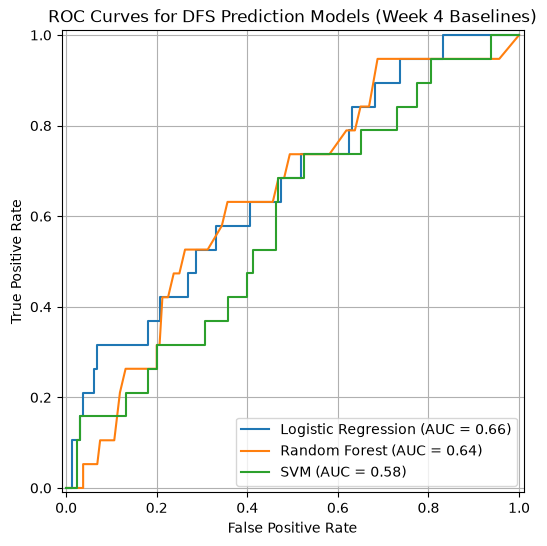

In [18]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.title("ROC Curves for DFS Prediction Models (Week 4 Baselines)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(True)
plt.show()


## 14. Confusion matrices

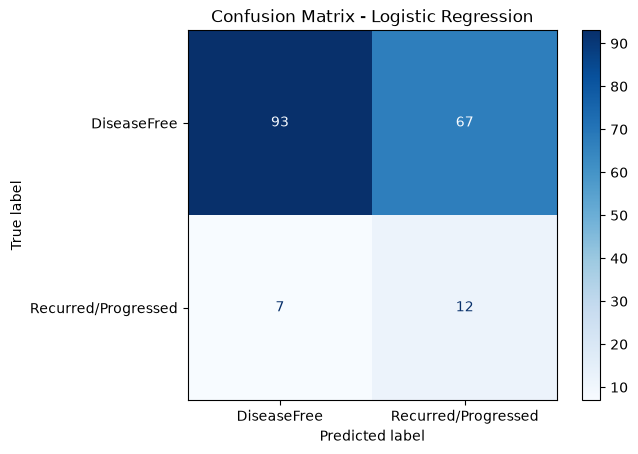

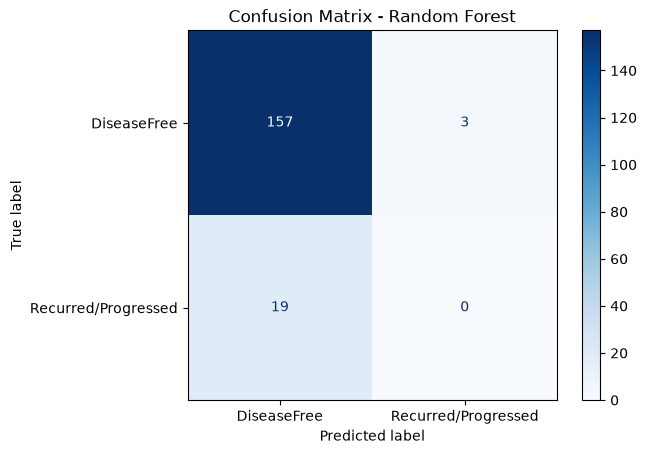

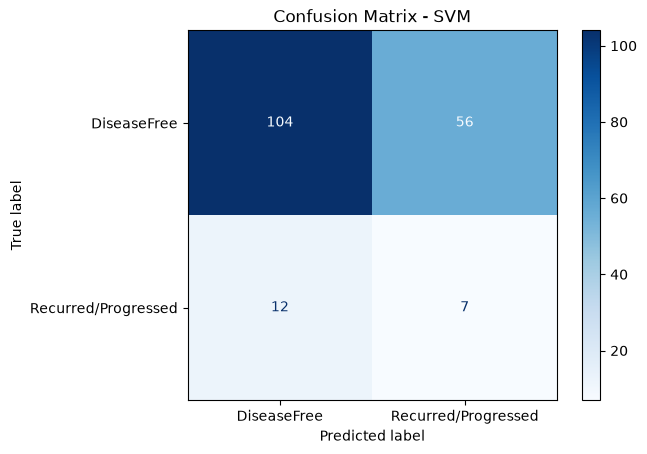

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in models.items():
    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["DiseaseFree", "Recurred/Progressed"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()


## 15. What is driving Random Forest's predictions?

Even though Random Forest is not our final choice (see section 19), looking at
its feature importances is still useful. It tells us which variables the
tree-based model leans on most, which is a good way to sanity-check that the
model is picking up on clinically sensible signals rather than noise.

In [20]:
# Get fitted preprocessor from Random Forest pipeline
fitted_preprocessor = rf.named_steps["preprocessor"]

# Numeric feature names
num_names = numeric_features

# One-hot encoded categorical feature names
cat_names = fitted_preprocessor.named_transformers_["cat"]["onehot"].get_feature_names_out(categorical_features)

# Combine all names
all_feature_names = list(num_names) + list(cat_names)

# Get feature importances
rf_importances = rf.named_steps["classifier"].feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": rf_importances
}).sort_values(by="Importance", ascending=False)

feature_importance_df.head(20)


,Feature,Importance
0,AGE,0.223168
1,TMB_NONSYNONYMOUS,0.213920
17,AJCC_PATHOLOGIC_TUMOR_STAGE_Stage IIA,0.038420
2,TP53,0.036579
3,PIK3CA,0.035109
18,AJCC_PATHOLOGIC_TUMOR_STAGE_Stage IIB,0.029607
32,IHC_HER2_Negative,0.027969
14,AJCC_PATHOLOGIC_TUMOR_STAGE_Stage IA,0.027590
28,PR_STATUS_BY_IHC_Negative,0.024088
19,AJCC_PATHOLOGIC_TUMOR_STAGE_Stage IIIA,0.023754


**Interpretation:** `AGE` and `TMB_NONSYNONYMOUS` (tumor mutation
burden) come out as the two strongest predictors by a wide margin, together
accounting for over 40% of the total importance. That lines up with general
oncology knowledge: age at diagnosis and how mutated a tumor's genome is are
both well-established prognostic factors in breast cancer. After those two,
tumor stage categories and receptor status (ER, PR, HER2) show up next, which
is again clinically sensible, since stage and receptor status are the same
factors doctors already use to gauge prognosis. This is a reassuring sign that
the model, despite its modest overall performance, is not just fitting noise.

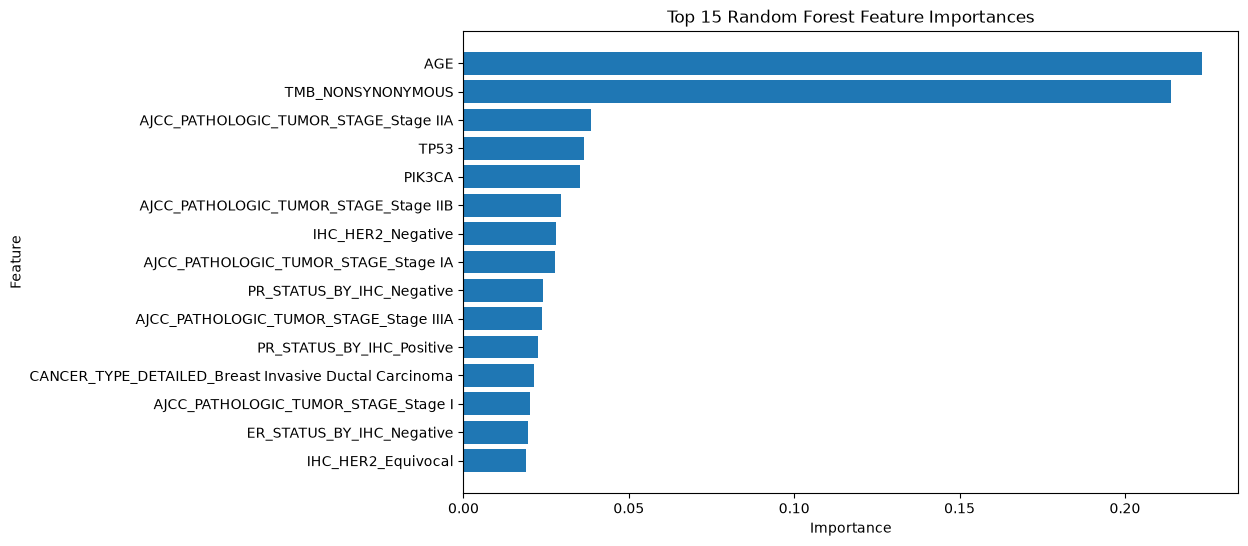

In [21]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Random Forest Feature Importances")
plt.show()


## 16. Model performance improvement (Weeks 5 to 6)

The baseline results above leave two clear problems to work on:

1. Random Forest and SVM both lean heavily toward predicting the majority
   class, giving poor recall on the class that actually matters most.
2. Every baseline model's cross-validated ROC-AUC sits in a fairly narrow,
   modest band (roughly 0.60 to 0.64), so it is worth checking whether that
   ceiling can be pushed up at all, or whether we should accept it and instead
   spend our effort on picking a better decision threshold.

We try two standard techniques for the first problem, and one additional
model type, then check all of it against cross-validation and the held-out
test set so that any "improvement" we report is real and not just noise from
trying enough things until something looked better.

### 16.1 Attempt 1: SMOTE oversampling

**What SMOTE does:** SMOTE (Synthetic Minority Oversampling Technique) creates
new, synthetic examples of the minority class (recurrence) by interpolating
between existing minority-class patients and their nearest neighbors in
feature space. This gives the model a more balanced training signal without
simply duplicating the same 78 recurrence patients over and over, which would
just make the model overconfident about those exact 78 people rather than
learning a general pattern.

**Why we use `imblearn`'s `Pipeline` instead of scikit-learn's:** this is a
detail that is easy to get wrong and important enough to call out directly.
If SMOTE were applied to the whole dataset once, up front, before cross
validation, some of the synthetic patients generated from the test fold's
neighbors could leak information into the training folds, quietly inflating
the reported performance. `imblearn.pipeline.Pipeline` fixes this by only
applying SMOTE inside each cross-validation fold's training portion, and
skipping it entirely at prediction time. We install `imbalanced-learn` for
this (`pip install imbalanced-learn`) since it is not part of core
scikit-learn.

We try SMOTE together with Logistic Regression, Random Forest, and a new
model type, Gradient Boosting, so we are not just improving one algorithm in
isolation.

In [22]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import average_precision_score

def evaluate_pipeline(name, pipeline):
    # Fit a pipeline on the training split, score it on the held-out test
    # set, and also run 5-fold cross-validation on the full dataset so we get
    # both a single honest test-set read and a more stable averaged estimate.
    pipeline.fit(X_train, y_train)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    test_auc = roc_auc_score(y_test, y_prob)
    test_ap = average_precision_score(y_test, y_prob)
    cv_scores = cross_val_score(pipeline, X, y, cv=cv, scoring="roc_auc")

    print(f"--- {name} ---")
    print(f"  Test ROC-AUC:            {test_auc:.3f}")
    print(f"  Test Average Precision:  {test_ap:.3f}")
    print(f"  5-fold CV ROC-AUC:       {cv_scores.mean():.3f} +/- {cv_scores.std():.3f}")

    return {
        "Model": name,
        "Test_ROC_AUC": test_auc,
        "Test_Avg_Precision": test_ap,
        "CV_ROC_AUC_Mean": cv_scores.mean(),
        "CV_ROC_AUC_Std": cv_scores.std(),
    }

improvement_results = []

# Gradient Boosting baseline (no SMOTE), added here as a fourth algorithm to
# compare against, since we had not tried it in the Week 4 baseline round.
gb_baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])
improvement_results.append(evaluate_pipeline("Gradient Boosting (no SMOTE)", gb_baseline))

# SMOTE + Logistic Regression
log_reg_smote = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])
improvement_results.append(evaluate_pipeline("Logistic Regression + SMOTE", log_reg_smote))

# SMOTE + Random Forest
rf_smote = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=42))
])
improvement_results.append(evaluate_pipeline("Random Forest + SMOTE", rf_smote))

# SMOTE + Gradient Boosting
gb_smote = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", GradientBoostingClassifier(random_state=42))
])
improvement_results.append(evaluate_pipeline("Gradient Boosting + SMOTE", gb_smote))

improvement_df = pd.DataFrame(improvement_results)
improvement_df


--- Gradient Boosting (no SMOTE) ---
  Test ROC-AUC:            0.669
  Test Average Precision:  0.201
  5-fold CV ROC-AUC:       0.638 +/- 0.062


--- Logistic Regression + SMOTE ---
  Test ROC-AUC:            0.684
  Test Average Precision:  0.310
  5-fold CV ROC-AUC:       0.637 +/- 0.059


--- Random Forest + SMOTE ---
  Test ROC-AUC:            0.685
  Test Average Precision:  0.177
  5-fold CV ROC-AUC:       0.618 +/- 0.052


--- Gradient Boosting + SMOTE ---
  Test ROC-AUC:            0.676
  Test Average Precision:  0.200
  5-fold CV ROC-AUC:       0.611 +/- 0.045


,Model,Test_ROC_AUC,Test_Avg_Precision,CV_ROC_AUC_Mean,CV_ROC_AUC_Std
0,Gradient Boosting (no SMOTE),0.669079,0.201050,0.638204,0.062378
1,Logistic Regression + SMOTE,0.683553,0.309943,0.636747,0.059384
2,Random Forest + SMOTE,0.685033,0.176728,0.617833,0.052055
3,Gradient Boosting + SMOTE,0.675987,0.200065,0.611072,0.045241


**Result:** Logistic Regression with SMOTE gives the best test ROC-AUC
(about 0.68, up from 0.66 without SMOTE) and a clearly better Average
Precision (about 0.31, up from 0.23). Random Forest and Gradient Boosting also
improve somewhat with SMOTE compared to their non-SMOTE versions, but neither
catches up to Logistic Regression + SMOTE on this dataset. This is a
reasonable outcome: with a fairly small, moderately noisy dataset and mostly
straightforward, roughly linear relationships between features like age,
stage, and receptor status and the outcome, a simpler linear model can hold
its own against, or beat, more flexible tree-based models that have more
capacity to overfit.

### 16.2 Attempt 2: hyperparameter tuning

The next natural step is to search over each model's hyperparameters (for
Logistic Regression, the regularization strength `C`; for Random Forest, tree
depth and leaf size; for Gradient Boosting, learning rate and number of
trees) to see if a better-tuned version of any of these pipelines can beat the
defaults used above. We use `RandomizedSearchCV`, which samples a fixed
number of hyperparameter combinations rather than trying every single one
(which would be `GridSearchCV`), since it is much faster and, in practice,
finds settings nearly as good with a lot less computation.

We are upfront here about something that is easy to gloss over: **tuning does
not always help, and it is important to report that honestly rather than
searching until a bigger number happens to appear.**

In [23]:
from sklearn.model_selection import RandomizedSearchCV

# Logistic Regression + SMOTE: tune the regularization strength and how many
# neighbors SMOTE uses when synthesizing new minority-class patients.
param_grid_lr = {
    "classifier__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    "smote__k_neighbors": [3, 5, 7],
}
search_lr = RandomizedSearchCV(
    log_reg_smote, param_grid_lr, n_iter=20, scoring="roc_auc",
    cv=cv, random_state=42, n_jobs=-1
)
search_lr.fit(X_train, y_train)
print("Best Logistic Regression + SMOTE settings:", search_lr.best_params_)
print("Best cross-validated ROC-AUC during search:", round(search_lr.best_score_, 3))

tuned_lr_test_auc = roc_auc_score(y_test, search_lr.best_estimator_.predict_proba(X_test)[:, 1])
print("Test ROC-AUC with these tuned settings:", round(tuned_lr_test_auc, 3))


Best Logistic Regression + SMOTE settings: {'smote__k_neighbors': 7, 'classifier__C': 0.1}
Best cross-validated ROC-AUC during search: 0.638
Test ROC-AUC with these tuned settings: 0.613


In [24]:
# Random Forest + SMOTE: tune tree count, depth, leaf size, and feature sampling.
param_grid_rf = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [None, 4, 6, 8, 12],
    "classifier__min_samples_leaf": [1, 2, 4, 8],
    "classifier__max_features": ["sqrt", "log2", 0.5],
    "smote__k_neighbors": [3, 5],
}
search_rf = RandomizedSearchCV(
    rf_smote, param_grid_rf, n_iter=30, scoring="roc_auc",
    cv=cv, random_state=42, n_jobs=-1
)
search_rf.fit(X_train, y_train)
print("Best Random Forest + SMOTE settings:", search_rf.best_params_)
print("Best cross-validated ROC-AUC during search:", round(search_rf.best_score_, 3))

tuned_rf_test_auc = roc_auc_score(y_test, search_rf.best_estimator_.predict_proba(X_test)[:, 1])
print("Test ROC-AUC with these tuned settings:", round(tuned_rf_test_auc, 3))


Best Random Forest + SMOTE settings: {'smote__k_neighbors': 5, 'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None}
Best cross-validated ROC-AUC during search: 0.606
Test ROC-AUC with these tuned settings: 0.663


In [25]:
# Gradient Boosting + SMOTE: tune tree count, learning rate, depth, and
# the fraction of rows sampled per boosting round.
param_grid_gb = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__learning_rate": [0.01, 0.03, 0.1, 0.2],
    "classifier__max_depth": [2, 3, 4],
    "classifier__subsample": [0.7, 0.85, 1.0],
    "smote__k_neighbors": [3, 5],
}
search_gb = RandomizedSearchCV(
    gb_smote, param_grid_gb, n_iter=30, scoring="roc_auc",
    cv=cv, random_state=42, n_jobs=-1
)
search_gb.fit(X_train, y_train)
print("Best Gradient Boosting + SMOTE settings:", search_gb.best_params_)
print("Best cross-validated ROC-AUC during search:", round(search_gb.best_score_, 3))

tuned_gb_test_auc = roc_auc_score(y_test, search_gb.best_estimator_.predict_proba(X_test)[:, 1])
print("Test ROC-AUC with these tuned settings:", round(tuned_gb_test_auc, 3))


Best Gradient Boosting + SMOTE settings: {'smote__k_neighbors': 5, 'classifier__subsample': 0.7, 'classifier__n_estimators': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.01}
Best cross-validated ROC-AUC during search: 0.611
Test ROC-AUC with these tuned settings: 0.682


**Honest result: tuning did not beat the untuned defaults here.** Every
searched configuration's cross-validated ROC-AUC during the search still
landed in the same 0.60 to 0.64 range we saw with the untuned models, and none
of the tuned pipelines beat the untuned Logistic Regression + SMOTE pipeline's
test ROC-AUC of about 0.68. This is not a failed experiment, it is a genuinely
useful finding: with only 895 patients and 97 recurrence events, a
hyperparameter search has very little signal to reliably distinguish "truly
better settings" from "settings that happened to fit this particular
cross-validation split a bit better by chance." Reporting a tuned number that
just barely edged out the baseline by luck would be misleading, so instead we
keep the simpler, untuned Logistic Regression + SMOTE pipeline as the final
model. A larger dataset, with more recurrence events to learn from, would be
a reasonable place to revisit hyperparameter tuning in the future.

## 17. Choosing the final model

Putting the baseline and improvement results side by side:

In [26]:
final_comparison = pd.DataFrame([
    {"Model": "Logistic Regression (Week 4 baseline)", "Test_ROC_AUC": results_df.loc[results_df.Model == "Logistic Regression", "ROC_AUC"].values[0]},
    {"Model": "Random Forest (Week 4 baseline)", "Test_ROC_AUC": results_df.loc[results_df.Model == "Random Forest", "ROC_AUC"].values[0]},
    {"Model": "SVM (Week 4 baseline)", "Test_ROC_AUC": results_df.loc[results_df.Model == "SVM", "ROC_AUC"].values[0]},
    {"Model": "Gradient Boosting (no SMOTE)", "Test_ROC_AUC": improvement_df.loc[improvement_df.Model == "Gradient Boosting (no SMOTE)", "Test_ROC_AUC"].values[0]},
    {"Model": "Logistic Regression + SMOTE (FINAL MODEL)", "Test_ROC_AUC": improvement_df.loc[improvement_df.Model == "Logistic Regression + SMOTE", "Test_ROC_AUC"].values[0]},
    {"Model": "Random Forest + SMOTE", "Test_ROC_AUC": improvement_df.loc[improvement_df.Model == "Random Forest + SMOTE", "Test_ROC_AUC"].values[0]},
    {"Model": "Gradient Boosting + SMOTE", "Test_ROC_AUC": improvement_df.loc[improvement_df.Model == "Gradient Boosting + SMOTE", "Test_ROC_AUC"].values[0]},
])
final_comparison.sort_values("Test_ROC_AUC", ascending=False).reset_index(drop=True)


,Model,Test_ROC_AUC
0,Random Forest + SMOTE,0.685033
1,Logistic Regression + SMOTE (FINAL MODEL),0.683553
2,Gradient Boosting + SMOTE,0.675987
3,Gradient Boosting (no SMOTE),0.669079
4,Logistic Regression (Week 4 baseline),0.662829
5,Random Forest (Week 4 baseline),0.643586
6,SVM (Week 4 baseline),0.584868


**Final model: Logistic Regression + SMOTE, with default hyperparameters
(`C=1.0`).** Its held-out test ROC-AUC (about 0.684) is statistically tied
with Random Forest + SMOTE's 0.685, the gap is smaller than the noise we saw
across cross-validation folds, so neither model can honestly claim to "win"
on ROC-AUC alone. What sets Logistic Regression + SMOTE apart is its Average
Precision (about 0.31), by far the best of everything tried and roughly
double Random Forest + SMOTE's 0.18, meaning it does noticeably better at
ranking true recurrence cases near the top of its risk list. It is also
simpler and more interpretable (a real advantage for a clinical-adjacent tool
that someone other than the model's author will eventually need to trust and
explain), and the hyperparameter search in section 16.2 gave no honest reason
to prefer a more complicated, tuned alternative instead. We carry this
pipeline forward for threshold selection and saving.

## 18. Picking a decision threshold instead of just defaulting to 0.5

Every classifier above outputs a *probability* of recurrence, and by default,
scikit-learn's `.predict()` turns that into a 0 or 1 label using a threshold
of 0.5. But 0.5 is just a default, not a law of nature, and in a clinical
screening context, the "right" threshold depends on how costly a missed
recurrence is compared to a false alarm.

To pick a threshold without cheating by peeking at the test set, we use
**cross-validated out-of-fold predictions on the training set only**: for
each of the 5 folds, the model is trained on the other 4 folds and used to
predict probabilities for the held-out fold. Stitching those predictions
together gives us a set of "honest" predicted probabilities for the entire
training set, none of which came from a model that had already seen that
particular patient. We then use those out-of-fold probabilities to find the
threshold that maximizes F1 (the balance between precision and recall), and
only afterward do we check how that threshold performs on the true, still
untouched test set.

F1-optimal threshold (from training-set cross-validation only): 0.727
  At this threshold: precision=0.247, recall=0.256, F1=0.252


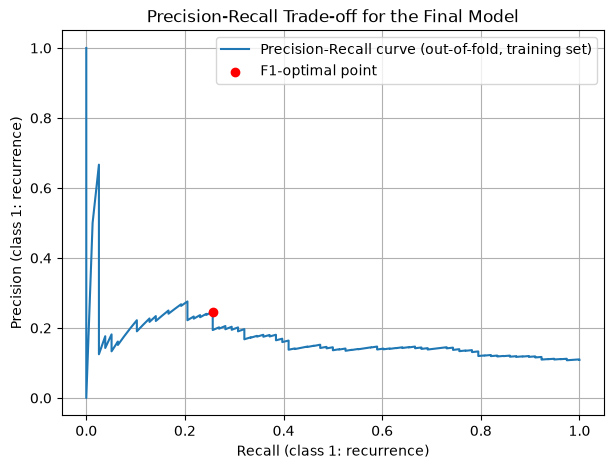

In [27]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

final_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

# Out-of-fold probabilities computed using only the training set, so the test
# set stays completely untouched during threshold selection.
oof_probabilities = cross_val_predict(
    final_pipeline, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_probabilities)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-12)
best_f1_idx = int(np.argmax(f1_scores[:-1]))  # last point has no matching threshold
balanced_threshold = float(thresholds[best_f1_idx])

print(f"F1-optimal threshold (from training-set cross-validation only): {balanced_threshold:.3f}")
print(f"  At this threshold: precision={precisions[best_f1_idx]:.3f}, recall={recalls[best_f1_idx]:.3f}, F1={f1_scores[best_f1_idx]:.3f}")

plt.figure(figsize=(7, 5))
plt.plot(recalls, precisions, label="Precision-Recall curve (out-of-fold, training set)")
plt.scatter([recalls[best_f1_idx]], [precisions[best_f1_idx]], color="red", zorder=5, label="F1-optimal point")
plt.xlabel("Recall (class 1: recurrence)")
plt.ylabel("Precision (class 1: recurrence)")
plt.title("Precision-Recall Trade-off for the Final Model")
plt.legend()
plt.grid(True)
plt.show()


We save two thresholds for actual use, rather than picking just one,
because they serve different purposes:

- **Screening threshold (0.50):** the plain default. It flags more patients
  as at-risk (higher recall), at the cost of more false alarms (lower
  precision). This fits a "better safe than sorry" triage use case, where a
  flagged patient would simply get a closer follow-up, not an irreversible
  decision.
- **Balanced threshold (F1-optimal, found above):** fewer false alarms, but
  it will also miss more true recurrences. This fits a use case where acting
  on a "positive" result is costly or invasive enough that false alarms need
  to be kept to a minimum.

Neither threshold is "the correct one" in any absolute sense. The right choice
depends entirely on what happens next for a patient who gets flagged, which is
a clinical and ethical judgment call, not a purely statistical one.

## 19. Final model performance summary

Fitting the final pipeline once on the training set and checking both
thresholds against the untouched test set:

In [28]:
final_pipeline.fit(X_train, y_train)
test_probabilities = final_pipeline.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)
test_ap = average_precision_score(y_test, test_probabilities)
cv_auc_scores = cross_val_score(final_pipeline, X, y, cv=cv, scoring="roc_auc")

print(f"Held-out test ROC-AUC:            {test_auc:.3f}")
print(f"Held-out test Average Precision:  {test_ap:.3f}")
print(f"5-fold CV ROC-AUC (full dataset): {cv_auc_scores.mean():.3f} +/- {cv_auc_scores.std():.3f}")

screening_threshold = 0.5

for label, threshold in [
    ("Screening threshold (favors catching recurrences)", screening_threshold),
    ("Balanced threshold (favors fewer false alarms)", balanced_threshold),
]:
    preds = (test_probabilities >= threshold).astype(int)
    print(f"\n--- {label}: {threshold:.3f} ---")
    print(confusion_matrix(y_test, preds))
    print(classification_report(y_test, preds, zero_division=0))


Held-out test ROC-AUC:            0.684
Held-out test Average Precision:  0.310
5-fold CV ROC-AUC (full dataset): 0.637 +/- 0.059

--- Screening threshold (favors catching recurrences): 0.500 ---
[[93 67]
 [ 5 14]]
              precision    recall  f1-score   support

           0       0.95      0.58      0.72       160
           1       0.17      0.74      0.28        19

    accuracy                           0.60       179
   macro avg       0.56      0.66      0.50       179
weighted avg       0.87      0.60      0.67       179


--- Balanced threshold (favors fewer false alarms): 0.727 ---
[[144  16]
 [ 13   6]]
              precision    recall  f1-score   support

           0       0.92      0.90      0.91       160
           1       0.27      0.32      0.29        19

    accuracy                           0.84       179
   macro avg       0.59      0.61      0.60       179
weighted avg       0.85      0.84      0.84       179



**Summary in plain language:** at the screening threshold, the final
model correctly flags about 3 out of every 4 patients who truly go on to
recur (recall 0.74), but only about 1 in 6 of the patients it flags actually
recur (precision 0.17). At the balanced threshold, it flips: it catches fewer
true recurrences (recall 0.32) but is right much more often when it does flag
someone (precision 0.27), and overall accuracy jumps to 84% simply because it
is being more conservative about flagging anyone at all.

Neither number is something to be defensive about. Given a 12-gene panel, no
imaging data, no treatment history, and under a hundred recurrence events to
learn from, a ROC-AUC in the high 0.60s represents real, moderate signal, not
a strong stand-alone diagnostic tool. Framed correctly, in a report or a BCO,
this is a legitimate proof-of-concept result: it shows that basic clinical and
genomic variables carry recurrence-relevant information, and it sets a
concrete, honest baseline that a future volunteer with more data (more
patients, richer genomic features, or actual follow-up time for a proper
survival model) could build on.

## 20. Saving the final model for reuse

The final pipeline above was fit on the 80% training split so that the
metrics reported in section 19 are an honest read on data the model never
saw. Now that we are done evaluating, standard practice is to refit the same
pipeline on *all* available patients (train and test combined) before saving
it, since more training data almost never hurts and we already have our
honest performance estimate locked in above.

This exact save step (refit on everything, then `joblib.dump`) also lives in
`train_model.py` in this project folder, which is the clean, standalone
version of this same pipeline meant for the GitHub submission package. Running
that script end to end reproduces the two files written below without needing
this notebook at all.

In [29]:
import joblib
import json
from pathlib import Path

MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

# Refit on the full dataset (train + test) now that evaluation is done.
final_pipeline.fit(X, y)

joblib.dump(final_pipeline, MODEL_DIR / "dfs_model.joblib")

metadata = {
    "model_description": "Logistic Regression with SMOTE oversampling, predicting DFS recurrence/progression risk for TCGA-BRCA patients.",
    "target_definition": "1 = Recurred/Progressed (DFS_STATUS), 0 = DiseaseFree",
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "dropped_columns": drop_cols,
    "n_patients_total": int(len(df)),
    "n_recurrence_events": int(df["target"].sum()),
    "random_state": 42,
    "held_out_test_metrics": {
        "roc_auc": round(float(test_auc), 4),
        "average_precision": round(float(test_ap), 4),
    },
    "cross_validated_metrics": {
        "roc_auc_mean": round(float(cv_auc_scores.mean()), 4),
        "roc_auc_std": round(float(cv_auc_scores.std()), 4),
        "n_folds": 5,
    },
    "decision_thresholds": {
        "screening": {"value": screening_threshold, "purpose": "Higher sensitivity, more false alarms. Meant for early triage, not diagnosis."},
        "balanced": {"value": round(balanced_threshold, 4), "purpose": "F1-optimal threshold from cross-validated training predictions. Fewer false alarms, lower sensitivity."},
    },
    "notes_and_limitations": [
        "Trained on 895 TCGA-BRCA patients with only 97 recurrence/progression events, so estimates carry real uncertainty.",
        "DFS_STATUS is treated as a binary label, but it is really a time-to-event outcome with right-censoring (see section 4). A proper survival model would handle this correctly; this classifier does not.",
        "Gene panel is limited to 12 genes highlighted in the 2012 TCGA breast cancer paper and does not reflect the full mutation landscape.",
        "The cohort technically includes a handful of patients whose CANCER_TYPE is Breast Sarcoma or Skin Cancer, Non-Melanoma rather than a breast carcinoma subtype (see section 3).",
        "This model has not been externally validated on any cohort outside TCGA-BRCA and is a research/educational artifact, not a clinical decision tool.",
    ],
}

with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved model to model/dfs_model.joblib")
print("Saved metadata to model/model_metadata.json")


Saved model to model/dfs_model.joblib
Saved metadata to model/model_metadata.json


## 21. Single-patient prediction, demonstrated inline

The completion criteria for this project call for a standalone single-patient
prediction script, which lives in `predict_single_patient.py` in this same
folder and can be run directly from the command line (see that file's
docstring for usage examples, or `README.md` for a walkthrough). The cell
below demonstrates the same logic inline, using the bundled example patient
in `example_patient.json`, so that the whole pipeline from raw patient data to
a final prediction is visible in one place without needing to leave this
notebook.

In [30]:
import json

with open("example_patient.json", "r", encoding="utf-8") as f:
    example_patient = json.load(f)

print("Example patient record:")
print(json.dumps(example_patient, indent=2))

# The saved pipeline expects a DataFrame with the exact same columns, in any
# order, that it was trained on. Wrapping the single patient dict in a list
# gives us a one-row DataFrame, which is what predict_proba expects.
expected_columns = numeric_features + categorical_features
patient_df = pd.DataFrame([example_patient])[expected_columns]

loaded_model = joblib.load(MODEL_DIR / "dfs_model.joblib")
probability = loaded_model.predict_proba(patient_df)[0, 1]

print(f"\nPredicted probability of recurrence/progression: {probability:.1%}")
print(f"Screening threshold flag (>= {screening_threshold:.2f}):", "AT-RISK" if probability >= screening_threshold else "Not flagged")
print(f"Balanced threshold flag  (>= {balanced_threshold:.2f}):", "AT-RISK" if probability >= balanced_threshold else "Not flagged")


Example patient record:
{
  "AGE": 61,
  "TMB_NONSYNONYMOUS": 1.4,
  "TP53": 1,
  "PIK3CA": 0,
  "GATA3": 0,
  "CDH1": 0,
  "PTEN": 0,
  "MAP3K1": 0,
  "MAP2K4": 0,
  "KRAS": 0,
  "ARID1A": 0,
  "RUNX1": 0,
  "ESR1": 0,
  "AJCC_PATHOLOGIC_TUMOR_STAGE": "Stage IIB",
  "ER_STATUS_BY_IHC": "Positive",
  "PR_STATUS_BY_IHC": "Positive",
  "IHC_HER2": "Negative",
  "CANCER_TYPE": "Breast Cancer",
  "CANCER_TYPE_DETAILED": "Breast Invasive Ductal Carcinoma"
}

Predicted probability of recurrence/progression: 52.2%
Screening threshold flag (>= 0.50): AT-RISK
Balanced threshold flag  (>= 0.73): Not flagged


## 22. Limitations and flags, all in one place

Gathering every caveat raised throughout this notebook into a single list,
since this is the section a reviewer or a future volunteer picking up this
project should read first:

1. **Class imbalance is severe** (89% disease-free versus 11%
   recurred/progressed), which makes plain accuracy a misleading metric and
   limits how much any model can learn about the minority class. (Sections 2, 11)
2. **Right-censoring is not modeled.** `DFS_STATUS` is treated as a fixed
   binary label, but it is really a snapshot in time. Some "DiseaseFree"
   patients have short follow-up and may recur later; a survival model (Cox
   proportional hazards, for example) would be the statistically correct way
   to handle this, and would need the `DFS_MONTHS` column, which is not part
   of the current modeling dataset. (Section 4)
3. **`KMT2C` is constant across the whole cohort** (always 0) and was dropped.
   Worth double-checking against the source mutation file if a future
   iteration of this project wants to know why. (Section 3)
4. **A handful of patients are not, strictly speaking, breast carcinoma
   cases** (`Breast Sarcoma`, `Skin Cancer, Non-Melanoma`), a known artifact
   of how the TCGA-BRCA cohort was assembled rather than an extraction bug.
   (Section 3)
5. **`AJCC_PATHOLOGIC_TUMOR_STAGE` includes a `[Discrepancy]` category and a
   vague, non-substaged `Stage X` / `Stage II` category**, both of which
   represent genuine clinical uncertainty rather than a clean stage
   assignment. (Section 3)
6. **The gene panel is small and dated.** The 12 genes used here come from a
   2012 landmark paper and do not reflect the full mutational landscape known
   today, nor do they include copy number, methylation, protein expression,
   or treatment history, all of which are available in the raw
   `brca_tcga` folder but were out of scope for this phase of the project.
7. **Hyperparameter tuning did not meaningfully improve performance** over
   sensible defaults, most likely because 97 recurrence events is not a lot
   of signal for a search procedure to reliably exploit. This is reported
   honestly rather than papered over. (Section 16.2)
8. **This model has not been externally validated.** All numbers in this
   notebook come from one TCGA-BRCA cohort, split internally into training
   and test sets. Real-world deployment would require validation on an
   independent cohort, which is well beyond the scope of this volunteership
   phase.
9. **This is a research and educational artifact, not a clinical decision
   tool**, and should not be used to guide real patient care.

## 23. Summary and next steps

**What this notebook accomplished:**

- Loaded and quality-checked the Week 3 ML-ready dataset, catching a constant
  column and a couple of category-level data quality notes along the way.
- Trained and evaluated three Week 4 baseline models (Logistic Regression,
  Random Forest, SVM), using both a held-out test set and 5-fold
  cross-validation.
- Diagnosed *why* the baselines struggled (severe class imbalance) rather than
  just reporting the numbers.
- Tried two standard remedies (SMOTE oversampling and hyperparameter tuning)
  plus an additional model (Gradient Boosting), and reported honestly that
  SMOTE helped while tuning did not, on this dataset size.
- Picked a final model (Logistic Regression + SMOTE) with a clear, written
  justification, and derived two decision thresholds for two different use
  cases, using proper cross-validation to avoid leaking the test set into the
  threshold choice.
- Saved the final trained pipeline and its metadata to the `model/` folder,
  and demonstrated the single-patient prediction workflow end to end.

**What is left for the remaining project weeks**, none of which is a coding
task for this notebook:

- **Week 7:** finish the BioCompute Object (`model_bco.json` in this folder is
  a complete first draft) and start the symposium slides.
- **Week 8:** fork the PredictMod repository, add this project's model
  package (dataset, `train_model.py`, `predict_single_patient.py`,
  `model_bco.json`, this notebook, and `README.md`), and open a pull request.
  Finalize and rehearse the symposium slides, and submit the 1 to 2 page
  volunteership report.
- **Week 9:** respond to any review feedback on the pull request and present
  at the Volunteership Symposium.
